# Eksploracyjna analiza danych Ames Housing - zajęcia 5


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("train.csv")
print("Wymiary zbioru:", df.shape)
df.head()

Wymiary zbioru: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.00,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.00,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.00,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.00,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.00,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


---
## 1. Pytania naprowadzające

**Zmienna docelowa:** `SalePrice`

**Rodzaje zmiennych w zbiorze:**
- **Liczbowe:** np. powierzchnie (`GrLivArea`, `LotArea`, `TotalBsmtSF`, `1stFlrSF`, `GarageArea`), rok budowy i remontu (`YearBuilt`, `YearRemodAdd`), liczba pokoi i łazienek (`TotRmsAbvGrd`, `BedroomAbvGr`, `FullBath`), a także sama zmienna docelowa `SalePrice`.
- **Porządkowe**: np. ogólna ocena jakości i stanu domu (`OverallQual`, `OverallCond` w skali 1–10) oraz oceny jakości elementów wykończenia zapisane tekstowo (`ExterQual`, `KitchenQual`, `BsmtQual`, `HeatingQC`, `FireplaceQu`, `PoolQC` w skali od `Po` do `Ex`).
- **Kategoryczne:** np. dzielnica (`Neighborhood`), typ budynku (`BldgType`), styl domu (`HouseStyle`), typ instalacji elektrycznej (`Electrical`), typ garażu (`GarageType`), warunki sprzedaży (`SaleCondition`), a także kodowana liczbowo klasa budynku `MSSubClass`. Kolumna `Id` pełni wyłącznie rolę identyfikatora transakcji.

In [ ]:
print("Liczba kolumn według typu danych:")
print(df.dtypes.value_counts())
print()
print("Typy danych wszystkich kolumn:")
print(df.dtypes.to_string())

Liczba kolumn według typu danych:
object     43
int64      35
float64     3
Name: count, dtype: int64

Typy danych wszystkich kolumn:
Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1      

In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.00,1201.00,1460.00,1460.00,1460.00,1460.00,1460.00,1452.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1379.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00
mean,730.50,56.90,70.05,10516.83,6.10,5.58,1971.27,1984.87,103.69,443.64,46.55,567.24,1057.43,1162.63,346.99,5.84,1515.46,0.43,0.06,1.57,0.38,2.87,1.05,6.52,0.61,1978.51,1.77,472.98,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.20
std,421.61,42.30,24.28,9981.26,1.38,1.11,30.20,20.65,181.07,456.10,161.32,441.87,438.71,386.59,436.53,48.62,525.48,0.52,0.24,0.55,0.50,0.82,0.22,1.63,0.64,24.69,0.75,213.80,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.50
min,1.00,20.00,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,0.00,0.00,0.00,334.00,0.00,0.00,334.00,0.00,0.00,0.00,0.00,0.00,0.00,2.00,0.00,1900.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.00
25%,365.75,20.00,59.00,7553.50,5.00,5.00,1954.00,1967.00,0.00,0.00,0.00,223.00,795.75,882.00,0.00,0.00,1129.50,0.00,0.00,1.00,0.00,2.00,1.00,5.00,0.00,1961.00,1.00,334.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.00
50%,730.50,50.00,69.00,9478.50,6.00,5.00,1973.00,1994.00,0.00,383.50,0.00,477.50,991.50,1087.00,0.00,0.00,1464.00,0.00,0.00,2.00,0.00,3.00,1.00,6.00,1.00,1980.00,2.00,480.00,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.00
75%,1095.25,70.00,80.00,11601.50,7.00,6.00,2000.00,2004.00,166.00,712.25,0.00,808.00,1298.25,1391.25,728.00,0.00,1776.75,1.00,0.00,2.00,1.00,3.00,1.00,7.00,1.00,2002.00,2.00,576.00,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.00
max,1460.00,190.00,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,5644.00,1474.00,2336.00,6110.00,4692.00,2065.00,572.00,5642.00,3.00,2.00,3.00,2.00,8.00,3.00,14.00,3.00,2010.00,4.00,1418.00,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.00


In [ ]:
df["BldgType"].value_counts()

,count
BldgType,
1Fam,1220
TwnhsE,114
Duplex,52
Twnhs,43
2fmCon,31


### Wnioski ze statystyk opisowych i typów danych
- Zbiór ma **1460 wierszy i 81 kolumn**: 38 kolumn liczbowych z czego 35 typu `int64`, 3 typu `float64` oraz 43 kolumny tekstowe/kategoryczne.
- Podstawowe statystyki pokazują sensowne zakresy wartości: cena `SalePrice` mieści się między **34 900 USD** a **755 000 USD** (średnia ok. **180 921 USD**), lata budowy (`YearBuilt`) obejmują okres **1872–2010**, a sprzedaż (`YrSold`) odbywała się w latach **2006–2010**.
- W `BldgType` dominują domy jednorodzinne (`1Fam`: 1220 szt.), są też szeregowce (`TwnhsE`: 114, `Twnhs`: 43), bliźniaki (`Duplex`: 52) i domy dwurodzinne (`2fmCon`: 31), ale nie ma mieszkań w blokach. Ewentualny model na tych danych będzie więc dotyczył wyłącznie domów Amerykańskich.

              liczba_brakow  procent_brakow
PoolQC                 1453           99.52
MiscFeature            1406           96.30
Alley                  1369           93.77
Fence                  1179           80.75
MasVnrType              872           59.73
FireplaceQu             690           47.26
LotFrontage             259           17.74
GarageType               81            5.55
GarageYrBlt              81            5.55
GarageFinish             81            5.55
GarageQual               81            5.55
GarageCond               81            5.55
BsmtExposure             38            2.60
BsmtFinType2             38            2.60
BsmtQual                 37            2.53
BsmtCond                 37            2.53
BsmtFinType1             37            2.53
MasVnrArea                8            0.55
Electrical                1            0.07


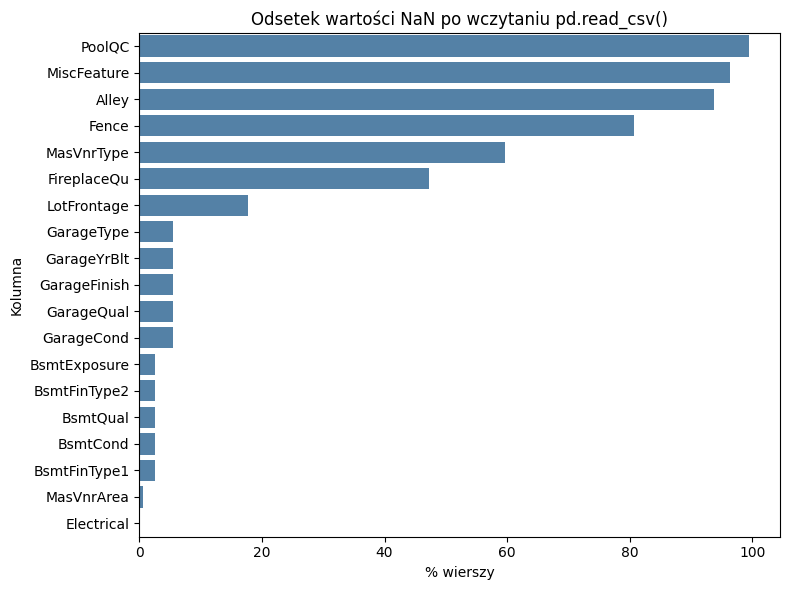

In [ ]:
braki = df.isna().sum()
braki = braki[braki > 0].sort_values(ascending=False)
braki_procent = (braki / len(df)) * 100

tabela_brakow = pd.DataFrame({
    "liczba_brakow": braki,
    "procent_brakow": braki_procent
})
print(tabela_brakow)

plt.figure(figsize=(8, 6))
sns.barplot(x=braki_procent.values, y=braki_procent.index, color="steelblue")
plt.title("Odsetek wartości NaN po wczytaniu pd.read_csv()")
plt.xlabel("% wierszy")
plt.ylabel("Kolumna")
plt.tight_layout()
plt.show()

### Wnioski dotyczące braków danych używając `data_description`
- Braki `NaN` pojawiają się w **19 kolumnach**, ale w większości przypadków nie są to błędy ani brakujące pomiary.

- Funkcja `pd.read_csv()` domyślnie zamienia tekst `"NA"` (oraz `"None"`) z pliku CSV na `NaN`.
- Z `data_description.txt` wynika, że `NA` oznacza tu brak danej cechy:
  - `PoolQC` (1453 braki, **99,52%**) — `NA` = brak basenu (tylko 7 domów ma basen).
  - `MiscFeature` (1406, **96,30%**) — `NA` = brak dodatkowych obiektów (np. szopy, kortu tenisowego).
  - `Alley` (1369, **93,77%**) — `NA` = brak dojazdu alejką.
  - `Fence` (1179, **80,75%**) — `NA` = brak ogrodzenia.
  - `MasVnrType` (872, **59,73%**) — wartość `None`/`NA` oznacza brak okładziny elewacyjnej.
  - `FireplaceQu` (690, **47,26%**) — `NA` = brak kominka.
  - `GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, `GarageCond` (po 81, **5,55%**) — `NA` = brak garażu.
  - `BsmtQual`, `BsmtCond`, `BsmtFinType1` (po 37, **2,53%**) oraz `BsmtExposure`, `BsmtFinType2` (po 38, **2,60%**) — `NA` = brak piwnicy (poza 1 dodatkowym brakiem przy istniejącej piwnicy).

  
- Prawdziwe braki danych to przede wszystkim `LotFrontage` (259 braków, **17,74%** oraz brak informacji o długości frontu działki przy ulicy), `MasVnrArea` (8 braków, **0,55%**) oraz `Electrical` (1 brak, **0,07%**).
- Z tego powodu nie wolno automatycznie usuwać wierszy z `NaN` ani wstawiać w nie średniej, ponieważ stracilibyśmy niemal cały zbiór albo zafałszowali dane. Braki wynikające z braku cechy trzeba zakodować jako osobną kategorię
 np. `"Brak"` albo `0`.

---
## 2. Analiza zmiennej docelowej (`SalePrice`)

In [ ]:
cena = df["SalePrice"]

cena_min = cena.min()
cena_max = cena.max()
srednia = cena.mean()
mediana = cena.median()
moda = cena.mode()[0]
q1 = cena.quantile(0.25)
q3 = cena.quantile(0.75)
iqr = q3 - q1
gorny_plot = q3 + 1.5 * iqr
dolny_plot = q1 - 1.5 * iqr
liczba_odstajacych = len(cena[cena > gorny_plot])

print("Min:", cena_min)
print("Max:", cena_max)
print("Średnia:", round(srednia, 2))
print("Mediana:", mediana)
print("Moda:", moda)
print("Q1 (25%):", q1)
print("Q3 (75%):", q3)
print("IQR (Q3 - Q1):", iqr)
print("Górny płot (Q3 + 1.5*IQR):", gorny_plot)
print("Dolny płot (Q1 - 1.5*IQR):", dolny_plot)
print("Liczba wartości odstających powyżej górnego płotu:", liczba_odstajacych)

Min: 34900
Max: 755000
Średnia: 180921.2
Mediana: 163000.0
Moda: 140000
Q1 (25%): 129975.0
Q3 (75%): 214000.0
IQR (Q3 - Q1): 84025.0
Górny płot (Q3 + 1.5*IQR): 340037.5
Dolny płot (Q1 - 1.5*IQR): 3937.5
Liczba wartości odstających powyżej górnego płotu: 61


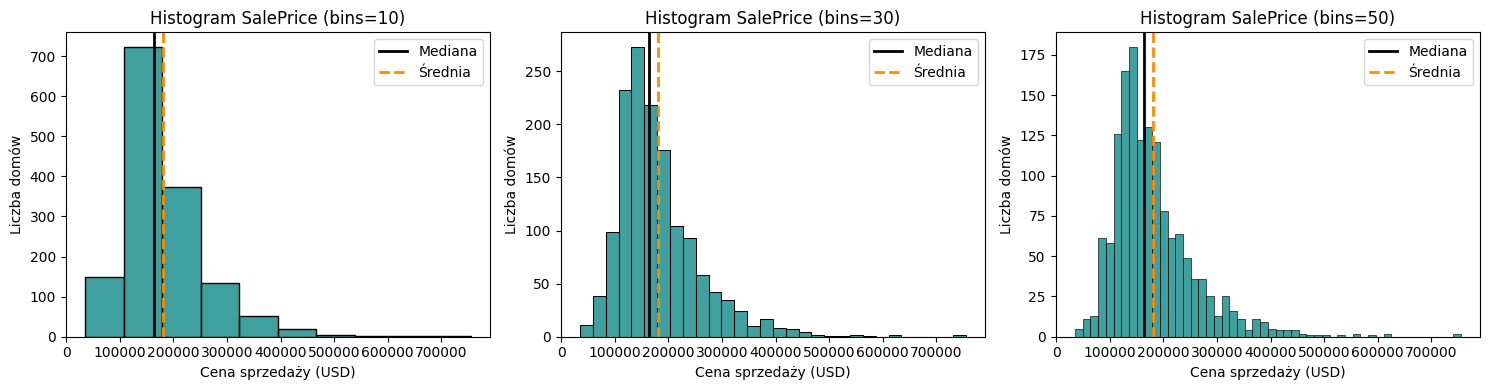

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, b in zip(axes, [10, 30, 50]):
    sns.histplot(cena, bins=b, ax=ax, color="teal")
    ax.axvline(mediana, color="black", linestyle="-", linewidth=2, label="Mediana")
    ax.axvline(srednia, color="darkorange", linestyle="--", linewidth=2, label="Średnia")
    ax.set_title(f"Histogram SalePrice (bins={b})")
    ax.set_xlabel("Cena sprzedaży (USD)")
    ax.set_ylabel("Liczba domów")
    ax.legend()

plt.tight_layout()
plt.show()

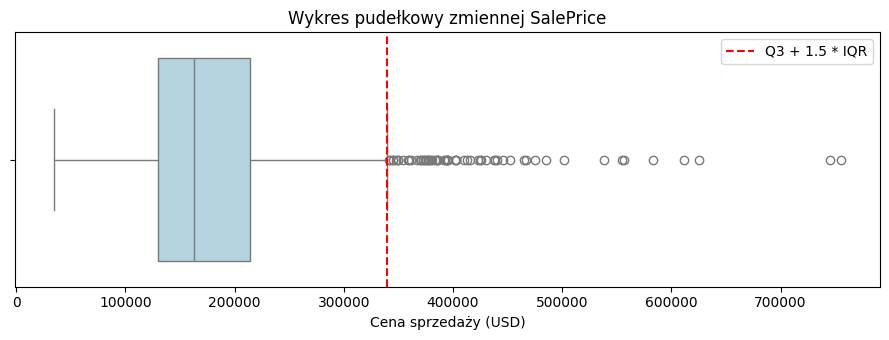

In [ ]:
plt.figure(figsize=(9, 3.5))
sns.boxplot(x=cena, color="lightblue")
plt.axvline(gorny_plot, color="red", linestyle="--", label="Q3 + 1.5 * IQR")
plt.title("Wykres pudełkowy zmiennej SalePrice")
plt.xlabel("Cena sprzedaży (USD)")
plt.legend()
plt.tight_layout()
plt.show()

### Wnioski z analizy SalePrice

- **Jaki jest rozkład cen?**
Rozkład cen jest wyraźnie prawostronnie skośny (asymetryczny) z długim ogonem w stronę wysokich kwot. Ceny zaczynają się od 34 900 USD, a kończą aż na 755 000 USD. Najczensrzaza cena w zbiorze to 140 000 USD. Połowa domów mieści się w przedziale między 129 975 USD (Q1) a 214 000 USD (Q3), więc IQR wynosi 84 025 USD. Przy bins=10 widać tylko ogólny zarys, przy bins=30 rozkład wygląda najczytelniej, a bins=50 dobrze pokazuje pojedyncze bardzo drogie domy.

- **Czy są wartości odstające? Co mogą oznaczać bardzo drogie domy?**
Na boxplocie widać wartości odstające wyłącznie po prawej stronie. Powyżej górnego płotu przy 340 037,50 USD jest 61 domów czyli około 4% zbioru. Poniżej dolnego płotu nie ma ani jednego. Bardzo drogie domy nie są błędami w danych,są  to po prostu luksusowe, duże nieruchomości o wysokim standardzie wykończenia.

- **Jaka jest średnia i mediana ceny?**
Średnia wynosi 180 921,20 USD, a mediana 163 000 USD. Średnia jest o prawie 18 tys. USD wyższa od mediany, bo w prawo mocno ciągną ją te najdroższe domy.

- **Czy ceny mają rozkład normalny?**
Nie, rozkład nie jest normalny. Histogramy są wyraźnie niesymetryczne i mają długi prawy ogon, a średnia różni się od mediany. Rozkład normalny musiałby być symetryczny w kształcie dzwonu.

---
## 3. Weryfikacja hipotezy „Większe domy są droższe”

In [ ]:
kolumny_powierzchnia = [col for col in df.columns if "Area" in col or "SF" in col]
print("Liczba kolumn związanych z powierzchnią:", len(kolumny_powierzchnia))
print(kolumny_powierzchnia)

Liczba kolumn związanych z powierzchnią: 14
['LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'PoolArea']


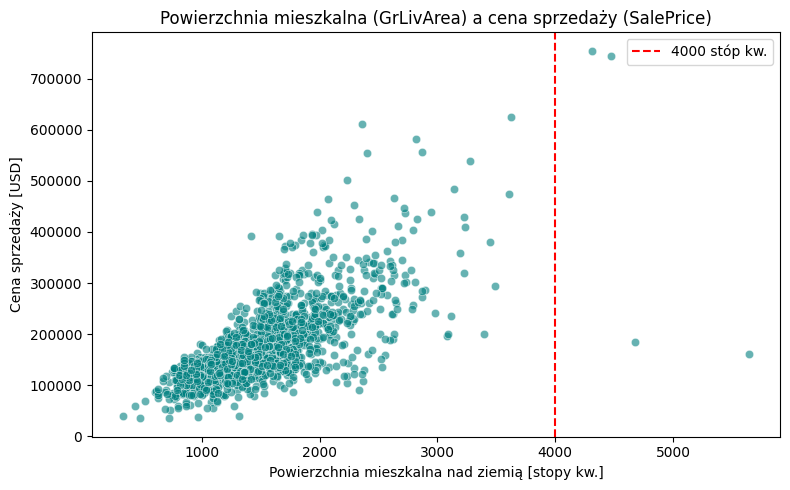

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6, color="teal")
plt.axvline(4000, color="red", linestyle="--", label="4000 stóp kw.")
plt.title("Powierzchnia mieszkalna (GrLivArea) a cena sprzedaży (SalePrice)")
plt.xlabel("Powierzchnia mieszkalna nad ziemią [stopy kw.]")
plt.ylabel("Cena sprzedaży [USD]")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
duze_domy = df[df["GrLivArea"] > 4000][["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition", "SaleType"]]
print(duze_domy)

        Id  GrLivArea  SalePrice  OverallQual SaleCondition SaleType
523    524       4676     184750           10       Partial      New
691    692       4316     755000           10        Normal       WD
1182  1183       4476     745000           10       Abnorml       WD
1298  1299       5642     160000           10       Partial      New


### Wnioski z wykresu `GrLivArea` vs `SalePrice` i nietypowych obserwacji
- Zależność między powierzchnią mieszkalną (`GrLivArea`) a ceną (`SalePrice`) jest wyraźna, dodatnia i w przybliżeniu liniowa. Większe domy rzeczywiście kosztują więcej, co wstępnie potwierdza postawioną hipotezę (korelacja wynosi **0,71**).
- Powyżej **4000 stóp²** znajdują się **4 nietypowe obserwacje**:
  - **Id 692** (4316 stóp², **755 000 USD**, `SaleCondition = Normal`) oraz **Id 1183** (4476 stóp², **745 000 USD**, `SaleCondition = Abnorml`) to dwa najdroższe domy w całym zbiorze i dobrze wpisują się w rosnący trend.
  - Natomiast **dwa największe domy w całym zbiorze** (**Id 524**: 4676 stóp² za **184 750 USD** oraz **Id 1299**: 5642 stóp² za **160 000 USD**) mają zaskakująco niską cenę, mimo najwyższej oceny jakości `OverallQual == 10`. Sprawdzenie kontekstu w `data_description.txt` wyjaśnia zagadkę: oba mają **`SaleCondition = Partial`** (`SaleType = New`), czyli były to transakcje częściowe przy nowych nieruchomościach, które nie odzwierciedlają pełnej ceny rynkowej. Te budynki nie były pewnie w pełni ukończone w momencie wyceniania domu.

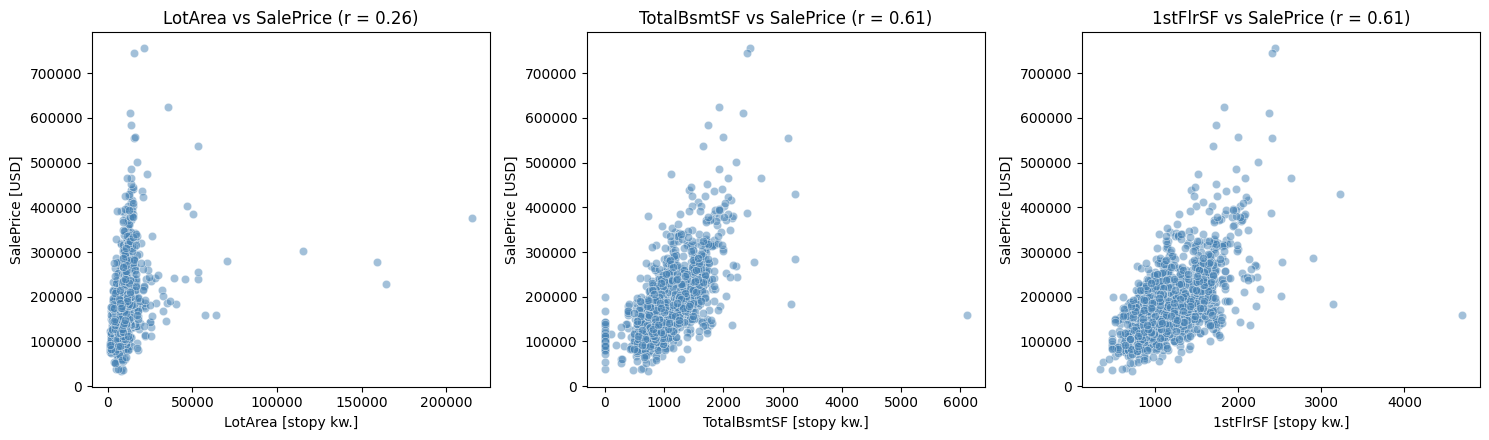

Korelacje wszystkich zmiennych powierzchniowych z SalePrice:
SalePrice       1.00
GrLivArea       0.71
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
MasVnrArea      0.48
BsmtFinSF1      0.39
WoodDeckSF      0.32
2ndFlrSF        0.32
OpenPorchSF     0.32
LotArea         0.26
BsmtUnfSF       0.21
PoolArea        0.09
BsmtFinSF2     -0.01
LowQualFinSF   -0.03
Name: SalePrice, dtype: float64


In [ ]:
powierzchnie_dodatkowe = ["LotArea", "TotalBsmtSF", "1stFlrSF"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, powierzchnie_dodatkowe):
    sns.scatterplot(data=df, x=col, y="SalePrice", ax=ax, alpha=0.5, color="steelblue")
    r = df[col].corr(df["SalePrice"])
    ax.set_title(f"{col} vs SalePrice (r = {r:.2f})")
    ax.set_xlabel(f"{col} [stopy kw.]")
    ax.set_ylabel("SalePrice [USD]")

plt.tight_layout()
plt.show()

korelacje_pow = df[kolumny_powierzchnia + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False)
print("Korelacje wszystkich zmiennych powierzchniowych z SalePrice:")
print(korelacje_pow)

### Porównanie wpływu `LotArea` z innymi rodzajami powierzchni
- Powierzchnia działki (`LotArea`) nie działa tak samo jak powierzchnia domu, jej korelacja z ceną wynosi zaledwie **0,26**. Na wykresie punktowym zdecydowana większość domów skupia się po lewej stronie (poniżej 25 tys. stóp², mediana to 9478,5 stóp²), a kilka ogromnych działek (ponad 100 tys. stóp², aż do 215 245 stóp²) sprzedało się za umiarkowane kwoty rzędu 228 950 - 375 000 USD. Sama wielkość działki nie gwarantuje wysokiej ceny, jeśli sam budynek nie jest duży lub luksusowy.
- Spośród porównywanych powierzchni najsilniejszy związek z ceną ma powierzchnia mieszkalna nad ziemią `GrLivArea` (`r = 0,71`).

 Kolejne pod względem siły korelacji są to:
  - `GarageArea` (powierzchnia garażu): **r = 0,62**,
  - `TotalBsmtSF` (powierzchnia całkowita piwnicy): **r = 0,61**,
  - `1stFlrSF` (powierzchnia pierwszej kondygnacji): **r = 0,61**.
  Zmienne pomocnicze, takie jak `PoolArea` (r = 0,09), `BsmtFinSF2` (r = -0,01) czy `LowQualFinSF` (r = -0,03), nie mają praktycznie żadnego związku z ceną.

---
## 4. Dodatkowe wykresy

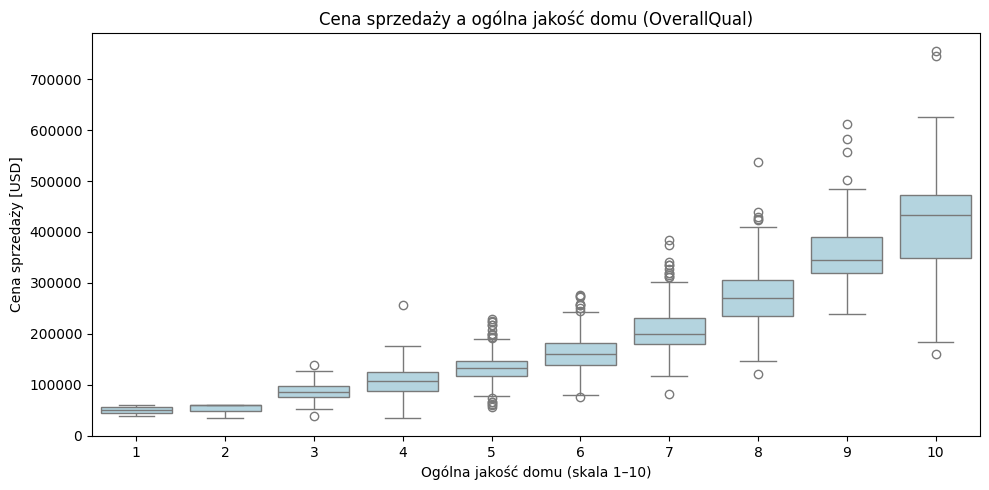

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color="lightblue")
plt.title("Cena sprzedaży a ogólna jakość domu (OverallQual)")
plt.xlabel("Ogólna jakość domu (skala 1–10)")
plt.ylabel("Cena sprzedaży [USD]")
plt.tight_layout()
plt.show()

## **Jakość domu (`OverallQual`) a cena (`SalePrice`):**
Wykres pudełkowy potwierdza monotoniczny, wykładniczy wzrost ceny wraz z jakością domu. Mediana ceny rośnie od **50 150 USD** dla oceny 1 do **432 390 USD** dla oceny 10. Jednocześnie przy ocenie `10` widać dwa punkty odstające poniżej 200 tys. USD, które zostały zidentyfikowane wcześniej jako największe domy w zbiorze sprzedane na zasadzie nieukończonej budowy.

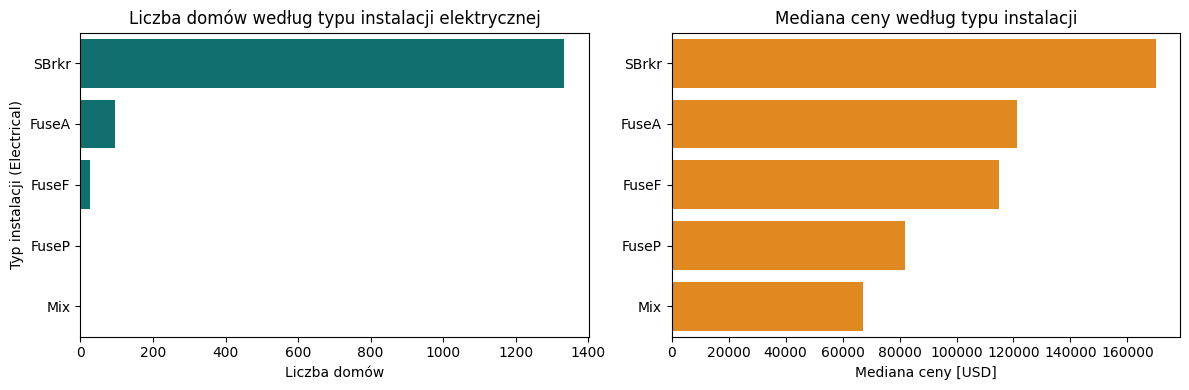

Electrical
SBrkr    1334
FuseA      94
FuseF      27
FuseP       3
Mix         1
NaN         1
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

kolejnosc = df["Electrical"].value_counts().index
sns.countplot(data=df, y="Electrical", order=kolejnosc, ax=axes[0], color="teal")
axes[0].set_title("Liczba domów według typu instalacji elektrycznej")
axes[0].set_xlabel("Liczba domów")
axes[0].set_ylabel("Typ instalacji (Electrical)")

sns.barplot(data=df, y="Electrical", x="SalePrice", order=kolejnosc, estimator=np.median, errorbar=None, ax=axes[1], color="darkorange")
axes[1].set_title("Mediana ceny według typu instalacji")
axes[1].set_xlabel("Mediana ceny [USD]")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print(df["Electrical"].value_counts(dropna=False))

## **Rozkład cechy kategorycznej (`Electrical`):**
 Niemal wszystkie domy czyli **1334 z 1460** ( 91,4% )  posiadają nowoczesną instalację z bezpiecznikami automatycznymi (`SBrkr`) o medianie ceny **170 000 USD**. Cecha ta prawie nie różnicuje domów i niewiele wniesie do modelu. Rzadkie kategorie ze starszymi bezpiecznikami topikowymi (`FuseA`: 94 domy, `FuseF`: 27 domów, `FuseP`: 3 domy, `Mix`: 1 dom) wiążą się ze znacznie niższą medianą ceny (**67 000–121 250 USD**), jednak przy małych liczebnościach rzędu `n = 1` czy `n = 3` do samej mediany trzeba podchodzić ostrożnie, gdyż wynika ona raczej z ogólnego wieku całego budynku.

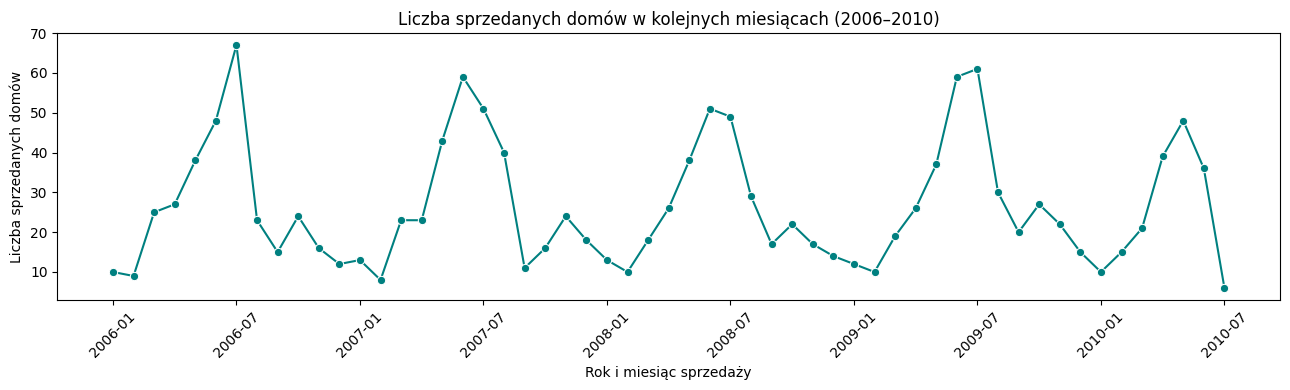

In [ ]:
df["RokMiesiac"] = df["YrSold"].astype(str) + "-" + df["MoSold"].astype(str).str.zfill(2)
sprzedaz_mies = df["RokMiesiac"].value_counts().sort_index()

plt.figure(figsize=(13, 4))
sns.lineplot(x=sprzedaz_mies.index, y=sprzedaz_mies.values, marker="o", color="teal")
plt.title("Liczba sprzedanych domów w kolejnych miesiącach (2006–2010)")
plt.xlabel("Rok i miesiąc sprzedaży")
plt.ylabel("Liczba sprzedanych domów")
plt.xticks(ticks=range(0, len(sprzedaz_mies), 6), labels=sprzedaz_mies.index[::6], rotation=45)
plt.tight_layout()
plt.show()

### **Sezonowość sprzedaży:**
Wykres liniowy wyraźnie uwidacznia cykliczną sezonowość na rynku nieruchomości. W każdym roku widoczne są wyraźne wzrosty transakcji latem (szczyty w czerwcu i lipcu, np. 67 transakcji w lipcu 2006 i 61 w lipcu 2009) oraz spadki zimą (do 8–10 transakcji w grudniu–styczniu). Gwałtowny spadek na samym końcu, czyli zaledwie 6 transakcji w `2010-07` nie oznacza załamania rynku, tylko koniec okresu zbierania danych treningowych.

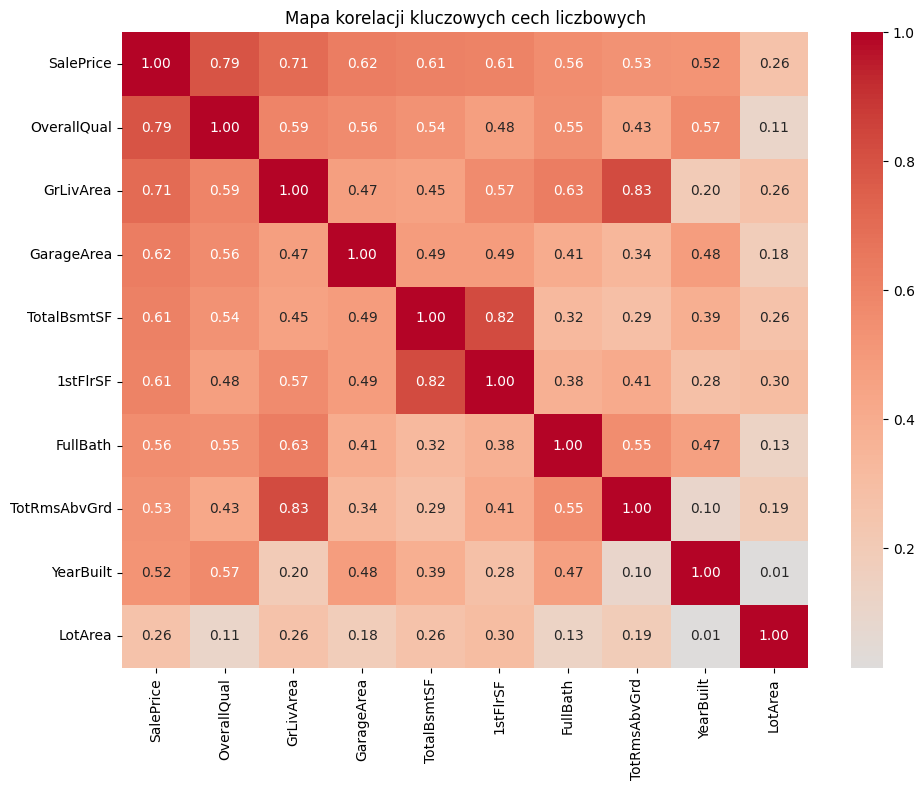

In [ ]:
kluczowe_cechy = [
    "SalePrice",
    "OverallQual",
    "GrLivArea",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "LotArea"
]
korelacje = df[kluczowe_cechy].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(korelacje, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Mapa korelacji kluczowych cech liczbowych")
plt.tight_layout()
plt.show()

## **Mapa ciepła korelacji:**
Najsilniej z ceną `SalePrice` korelują ogólna jakość wykończenia `OverallQual` (**0,79**) oraz powierzchnia mieszkalna `GrLivArea` (**0,71**), a także `GarageArea` (**0,62**), `TotalBsmtSF` (**0,61**) i `1stFlrSF` (**0,61**). Widać również bardzo silną współliniowość pomiędzy samymi cechami opisującymi wielkość nieruchomości (`GrLivArea` i `TotRmsAbvGrd`: **0,83**; `TotalBsmtSF` i `1stFlrSF`: **0,82**). Rok budowy `YearBuilt` ma umiarkowaną dodatnią korelację z ceną (**0,52**), a powierzchnia działki `LotArea` koreluje z ceną najsłabiej (**0,26**).